# 04 · Binning, WoE and IV: which features go into the scorecard

## What this notebook is, and where it sits in the project

Notebook 03 fixed the loans: a train sample (75,302 loans, 2016 to 2019), a test sample (32,273 loans, same years) and an out-of-time sample (48,150 loans, 2020 to July 2021). This notebook starts Phase 3, the scorecard itself, by deciding **which features it uses and how each one is grouped**.

A classic credit scorecard (Siddiqi, chapters 9 and 10) does not feed raw numbers into a model. It first cuts every feature into a few groups called *bins* (for example "0 previous loans", "1", "2", "3 to 5", "6 or more"), measures how risky each bin is, and replaces the raw value with that risk measure, the *weight of evidence* (WoE). The model then learns from WoE values. This makes the scorecard robust to outliers, handles missing values as their own group, and lets a credit officer read every bin as "this group defaults more or less than average".

The notebook:

1. Loads the candidate features through the registry and adds two derived features, `country_bureau_grade` and `income_vs_country_median` (D-017).
2. Fits the bins on the **train sample only**.
3. Ranks the features by *information value* (IV).
4. Reads the bins of the strongest features and checks they make business sense.
5. Checks that each feature's pattern holds **inside** each country, not only on the pooled data.
6. Checks two questions raised earlier: language as a proxy (D-016) and the June 2017 change in liabilities (D-015).
7. Checks each feature's stability from train to test and to the out-of-time period (PSI).
8. Removes features that duplicate each other (correlation and VIF).
9. Ends with a shortlist of features for the scorecard model in notebook 05.

## How to read this notebook

As before, every step has: **Why this step**, **the code**, **What the result shows**, **Recommended action**.

**One rule this notebook follows strictly: the out-of-time sample stays blind.** Features are chosen with the train and test samples. From the out-of-time sample we only compare *how the feature values are distributed* (PSI), never *how well a feature predicts default there*. If we picked features by their out-of-time performance, the out-of-time test in notebook 05 would no longer be an independent test: we would have tuned the model to it.

The notebook reads the warehouse read-only. It writes two files to `data/processed/` (git-ignored, rebuilt by rerunning): `binning_process.pkl` (the fitted bins) and `scorecard_shortlist.json` (the chosen features).

## Key terms used in this notebook

| Term | Meaning |
|---|---|
| **Bin** | A group of values of one feature, for example `IncomeTotal` from 800 to 1,200. Categories can be grouped too, for example several home-ownership types in one bin. |
| **Binning (coarse classing)** | Choosing the bins. Here done by `optbinning`, which finds the cut points that separate goods and bads best, under the rules in step 2. |
| **Event rate** | The default rate inside one bin. |
| **WoE (weight of evidence)** | For one bin: `ln(share of all goods in the bin / share of all bads in the bin)`. Positive WoE = the bin is safer than average; negative = riskier; 0 = average. |
| **IV (information value)** | One number per feature: how strongly its bins separate goods from bads. `IV = sum over bins of (share of goods - share of bads) x WoE`. |
| **Monotonic trend** | The default rate only goes up (or only down) from bin to bin. Required where economics expects it: more previous loans repaid should not make a borrower riskier and then safer again. |
| **PSI (population stability index)** | How much the share of loans in each bin has moved between two samples. Same formula as IV, but comparing two periods instead of goods and bads. Below 0.10 stable, 0.10 to 0.25 worth watching, above 0.25 a real shift. |
| **Correlation (of WoE)** | Whether two features rank loans the same way. Two features that say the same thing make the model unstable and harder to explain. |
| **VIF (variance inflation factor)** | How well one feature can be predicted from all the others together. Above 5 means it mostly repeats them. |
| **Simpson's paradox** | A pattern that appears in pooled data but disappears or reverses inside every group. Here: a feature that only looks predictive because its values differ by country. |
| **Spearman rank correlation** | Whether two lists go up and down together in the same order, from -1 (exact opposite order) to +1 (same order). |
| **Shortlist** | The features passed to the model in notebook 05. |

## Step 0. Setup

### Why this step
Load the libraries, open the warehouse read-only and load the registry. `optbinning` does the binning; `statsmodels` computes VIF. The project package `pdengine` provides the registry and the derived features.

In [1]:
import json
import logging
import sys
import warnings
from pathlib import Path

import duckdb                    # SQL engine holding the warehouse
import matplotlib.pyplot as plt  # charts
import numpy as np               # maths on arrays
import pandas as pd              # tables
from optbinning import BinningProcess                                      # binning + WoE
from statsmodels.stats.outliers_influence import variance_inflation_factor  # VIF

warnings.filterwarnings("ignore")   # optbinning's solver libraries print version notices; not errors
logging.disable(logging.WARNING)

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src" / "pdengine").exists())
DB = ROOT / "data" / "bondora.duckdb"
OUT_DIR = ROOT / "data" / "processed"
SAMPLES = OUT_DIR / "model_samples.parquet"
assert DB.exists(), "Warehouse missing: run  python -m pdengine.warehouse"
assert SAMPLES.exists(), "Samples missing: run notebooks/03_target_and_samples.ipynb"

try:
    from pdengine.features import add_derived
    from pdengine.registry import candidate_features, check_model_columns, load_registry
except ImportError:   # package not installed in this environment: use src/ directly
    sys.path.insert(0, str(ROOT / "src"))
    from pdengine.features import add_derived
    from pdengine.registry import candidate_features, check_model_columns, load_registry

con = duckdb.connect(str(DB), read_only=True)


def sql(query: str) -> pd.DataFrame:
    """Run a SQL query on the warehouse and return a pandas table."""
    return con.execute(query).df()


reg = load_registry()
RAW = candidate_features(reg)          # raw columns a model may use
DERIVED = list(reg.derived)            # engineered features registered in the YAML

BLUE, GREY, ORANGE = "#2a78d6", "#b5b3ad", "#d97a2b"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold",
})
print(f"Raw candidates: {len(RAW)}   Derived: {DERIVED}")

Raw candidates: 20   Derived: ['country_bureau_grade', 'income_vs_country_median']


### What the result shows
20 raw candidate features after D-009, D-012, D-014, D-015 and D-016, plus two derived features, `country_bureau_grade` and `income_vs_country_median` (D-017).

### Recommended action
None.

## Step 1. Build the feature matrix for all three samples

### Why this step
We load the candidate features for every sample loan, add the derived feature, and pass the column list through `check_model_columns` before anything else, exactly as notebook 03 showed. The sample labels and the target come from `model_samples.parquet`, so the loans are the same as in notebook 03.

**`country_bureau_grade` (D-017).** Notebook 03 showed that each bureau score exists only for its own country: `CreditScoreEeMini` for Estonia and `CreditScoreFiAsiakasTietoRiskGrade` for Finland. Binned on the pooled data, most of each score's bins just say "not this country", which repeats `Country`. The derived feature combines them into one: `EE_1000`, `EE_800`, ..., `FI_3`, `FI_RL2`, ..., and `ES` for Spain (no usable bureau score, D-014). One feature then carries both the country risk and the bureau grade inside each country.

**`income_vs_country_median` (D-017).** `IncomeTotal` divided by the median income of the borrower's country in the train sample (Estonia 1,000, Spain 1,350, Finland 2,036 euros a month). Step 5 shows why raw income cannot be used: Finnish incomes are about twice Estonian ones, and Finland defaults more, so pooled, "high income" mostly means "Finnish". The medians are frozen in the code, so a new application is compared with the same reference; the code below checks they still match the train sample.

Both functions live in `src/pdengine/features.py`, so the scoring API will compute them the same way.

Finally, the column types are set: codes such as `Education` or `HomeOwnershipType` are categories (a code 4 is not "twice" a code 2), while amounts and counts are numbers.

In [2]:
samples = pd.read_parquet(SAMPLES).set_index("loan_key")
con.register("sample_keys", samples.reset_index()[["loan_key"]])
cols = ", ".join(f'"{c}"' for c in RAW)
X = (sql(f"SELECT loan_key, {cols} FROM loans JOIN sample_keys USING (loan_key)")
     .set_index("loan_key").loc[samples.index])
X = add_derived(X)                       # adds country_bureau_grade, income_vs_country_median
FEATURES = list(X.columns)
check_model_columns(FEATURES, reg)       # the leakage guard
y, sample = samples["y"], samples["sample"]

# Column types for binning.
CATEGORICAL = ["VerificationType", "Country", "Education", "EmploymentDurationCurrentEmployer",
               "HomeOwnershipType", "ApplicationSignedWeekday",
               "CreditScoreFiAsiakasTietoRiskGrade", "country_bureau_grade"]
X["NewCreditCustomer"] = X["NewCreditCustomer"].astype(int)          # True/False -> 1/0
X["CreditScoreEeMini"] = X["CreditScoreEeMini"].astype(float)        # nullable int -> float
for c in CATEGORICAL:                                                # codes -> text, keep empties
    X[c] = X[c].astype("string").astype(object).where(X[c].notna(), np.nan)

is_train, is_test, is_oot = sample.eq("train"), sample.eq("test"), sample.eq("oot")

# The frozen country medians must equal the medians of the train sample.
from pdengine.features import TRAIN_MEDIAN_INCOME
train_median = X[is_train].groupby("Country")["IncomeTotal"].median().to_dict()
assert train_median == TRAIN_MEDIAN_INCOME, train_median

print(f"X: {X.shape[0]:,} loans x {X.shape[1]} features (passed check_model_columns)")
print(f"train {is_train.sum():,}  test {is_test.sum():,}  oot {is_oot.sum():,}")
X.loc[is_train, "country_bureau_grade"].value_counts().head(12)

X: 155,725 loans x 22 features (passed check_model_columns)
train 75,302  test 32,273  oot 48,150


country_bureau_grade
EE_1000    34104
ES         13290
FI_3        7421
FI_4        4903
EE_800      3370
EE_900      2926
FI_2        2123
FI_5        1847
EE_700      1448
EE_600      1365
FI_RL2      1053
FI_RL1       523
Name: count, dtype: int64

### What the result shows
The matrix has 155,725 loans and 22 features and passes the leakage guard; the frozen country medians match the train sample. The most common `country_bureau_grade` values are `EE_1000` (the top Estonian grade), `ES`, and the middle Finnish grades.

### Recommended action
None. Steps 2 to 7 use only `X[is_train]` to learn anything from the target.

## Step 2. Fit the bins on the train sample

### Why this step
The bins are part of the model: they are learned from data, so they are learned **only from the train sample**. The test sample then shows whether they hold on loans they have not seen.

The rules given to `optbinning`:

* **At least 5% of train loans in every bin** (`min_bin_size=0.05`, roadmap Phase 3 and Siddiqi's usual minimum). Smaller bins give unstable default rates.
* **Monotonic trend for numeric features** (`auto_asc_desc`): the default rate must only rise or only fall across the bins; optbinning picks the direction that fits the data. This is what a credit officer expects for amounts, income, liabilities and previous loans.
* **Two exceptions:** `ApplicationSignedHour` and `MonthlyPaymentDay` may have one peak or valley (`auto`), because there is no reason for risk to move in one direction across the hours of the day or the days of the month.
* **Missing values get their own bin** automatically, with their own WoE.
* **Categories** are grouped by similar default rate, with the same 5% minimum.

In [3]:
NON_MONOTONIC = ["ApplicationSignedHour", "MonthlyPaymentDay"]
fit_params = {c: {"monotonic_trend": "auto" if c in NON_MONOTONIC else "auto_asc_desc"}
              for c in FEATURES if c not in CATEGORICAL}

bp = BinningProcess(FEATURES, categorical_variables=CATEGORICAL, min_bin_size=0.05,
                    binning_fit_params=fit_params)
bp.fit(X[is_train], y[is_train])      # train sample only

iv = (bp.summary().set_index("name")[["dtype", "n_bins", "iv"]]
        .astype({"n_bins": int, "iv": float}).sort_values("iv", ascending=False))
print(f"Fitted {len(iv)} features on {is_train.sum():,} train loans")

Fitted 22 features on 75,302 train loans


### What the result shows
All 22 features were binned. The next step reads the results.

### Recommended action
None.

## Step 3. Information value: how much does each feature tell us?

### Why this step
IV ranks the features by how well their bins separate goods from bads. Siddiqi's usual reading:

| IV | Strength |
|---|---|
| below 0.02 | not predictive |
| 0.02 to 0.10 | weak |
| 0.10 to 0.30 | medium |
| above 0.30 | strong |
| above 0.50 | suspiciously strong: check for leakage before using |

We also compute IV on the **test** sample, using the bins learned on train. If a feature's test IV is far below its train IV, its bins were fitted to noise in the train sample.

In [4]:
def bin_labels(mask: pd.Series) -> pd.DataFrame:
    """Bin label of every feature for the loans in mask (bins learned on train)."""
    return bp.transform(X[mask], metric="bins").set_index(X.index[mask])


def iv_on(labels: pd.Series, target: pd.Series) -> float:
    """IV of a feature on any sample, from its bin labels and the target.

    0.5 is added to every count so a bin with no goods or no bads does not give log(0).
    """
    t = pd.DataFrame({"bin": labels.values, "y": target.values}).groupby("bin")["y"].agg(["sum", "count"])
    bad, good = t["sum"] + 0.5, t["count"] - t["sum"] + 0.5
    pb, pg = bad / bad.sum(), good / good.sum()
    return float(((pg - pb) * np.log(pg / pb)).sum())


BINS = {"train": bin_labels(is_train), "test": bin_labels(is_test), "oot": bin_labels(is_oot)}
iv["iv_test"] = [iv_on(BINS["test"][c], y[is_test]) for c in iv.index]
iv["strength"] = pd.cut(iv["iv"], [-1, 0.02, 0.10, 0.30, 0.50, 99],
                        labels=["not predictive", "weak", "medium", "strong", "check (>0.5)"])
iv[["iv", "iv_test"]] = iv[["iv", "iv_test"]].round(3)
iv

,dtype,n_bins,iv,iv_test,strength
name,,,,,
country_bureau_grade,categorical,5,0.572,0.567,check (>0.5)
Country,categorical,3,0.523,0.527,check (>0.5)
CreditScoreEeMini,numerical,2,0.512,0.507,check (>0.5)
NoOfPreviousLoansBeforeLoan,numerical,6,0.193,0.180,medium
AmountOfPreviousLoansBeforeLoan,numerical,7,0.171,0.160,medium
NewCreditCustomer,numerical,2,0.166,0.150,medium
MonthlyPaymentDay,numerical,9,0.115,0.140,medium
HomeOwnershipType,categorical,5,0.092,0.097,weak
CreditScoreFiAsiakasTietoRiskGrade,categorical,2,0.092,0.085,weak


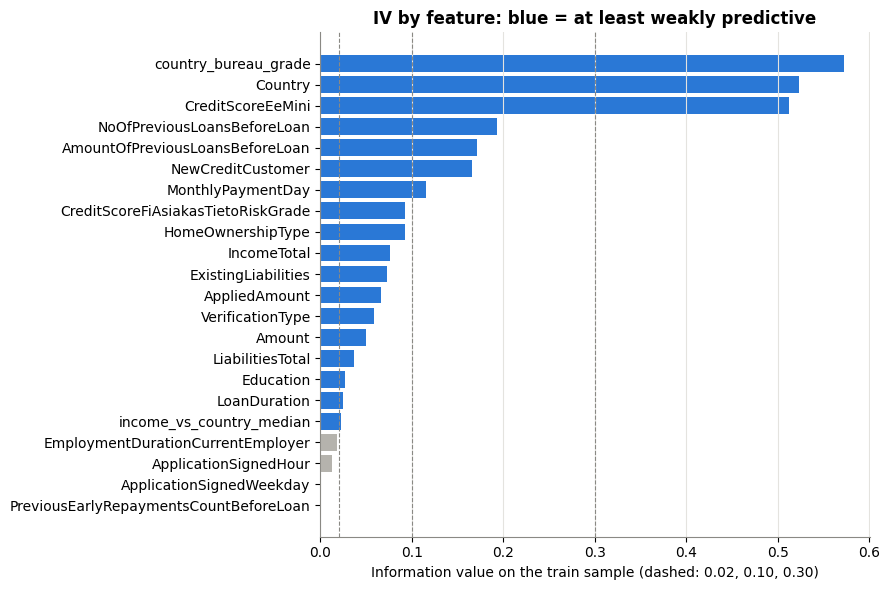

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
order = iv.sort_values("iv")
ax.barh(order.index, order["iv"], color=[BLUE if v >= 0.02 else GREY for v in order["iv"]])
for x in (0.02, 0.10, 0.30):
    ax.axvline(x, color="#8a8984", linewidth=0.8, linestyle="--")
ax.set_xlabel("Information value on the train sample (dashed: 0.02, 0.10, 0.30)")
ax.set_title("IV by feature: blue = at least weakly predictive")
ax.grid(axis="x", color="#e4e3df"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### What the result shows
* **Three strong features, all about country:** `country_bureau_grade` (0.57), `Country` (0.52) and `CreditScoreEeMini` (0.51). Their IV is above 0.5, so the rule says check for leakage first. They are not leaks: country is known on the application day, and the risk gap between countries is real and large (in train, about 19% default in Estonia, 42% in Finland, 57% in Spain, notebook 03). The derived feature is the strongest because it adds the bureau grade inside each country.
* **Medium:** previous loans with Bondora (`NoOfPreviousLoansBeforeLoan` 0.19, `AmountOfPreviousLoansBeforeLoan` 0.17, `NewCreditCustomer` 0.17) and `MonthlyPaymentDay` (0.12).
* **Weak (0.02 to 0.10):** home ownership, the Finnish grade on its own, income, liabilities, the loan amounts, verification type, education, loan duration and `income_vs_country_median` (0.022).
* **Not predictive (below 0.02):** employment duration (0.018), application hour (0.013), weekday (0.001) and `PreviousEarlyRepaymentsCountBeforeLoan` (0, one bin only: about 95% of train loans have 0, so no second bin can reach 5%).
* **Test IV is close to train IV for every feature** (within 0.025; the largest gap is `MonthlyPaymentDay`, 0.115 on train and 0.140 on test). The bins generalise to unseen loans from the same years; nothing was fitted to noise.

### Recommended action
* Drop the four features below 0.02.
* Keep the three country features for now. Step 7 picks one of them, because they say almost the same thing.

## Step 4. Read the bins: do they make business sense?

### Why this step
A scorecard must be explainable. Before trusting a feature, we look at its bins and ask whether a credit officer would agree with the pattern. A pattern that makes no sense is often a data problem, not a discovery.

Below: the binning table of the strongest feature, then the default rate per bin for six features.

In [6]:
def table(name: str) -> pd.DataFrame:
    """Binning table of one feature (train), without optbinning's empty Special/Missing rows."""
    t = bp.get_binned_variable(name).binning_table.build().drop(index="Totals")
    t = t[t["Count"] > 0][["Bin", "Count", "Count (%)", "Event rate", "WoE", "IV"]]
    t["Bin"] = t["Bin"].astype(str)
    return t.round({"Count (%)": 3, "Event rate": 3, "WoE": 3, "IV": 3})


table("country_bureau_grade")

,Bin,Count,Count (%),Event rate,WoE,IV
0,['EE_missing' 'FI_8' 'EE_1000'],34106,0.453,0.165,0.835023,0.260
1,['EE_900' 'FI_1' 'EE_800' 'EE_700' 'FI_RL1' 'E...,10085,0.134,0.266,0.234401,0.007
2,['FI_2' 'FI_6' 'FI_3' 'FI_RL2'],10860,0.144,0.392,-0.343222,0.018
3,['FI_4'],4903,0.065,0.476,-0.688656,0.034
4,['FI_5' 'FI_RL4' 'FI_missing' 'ES' 'FI_7' 'FI_...,15348,0.204,0.567,-1.054084,0.253


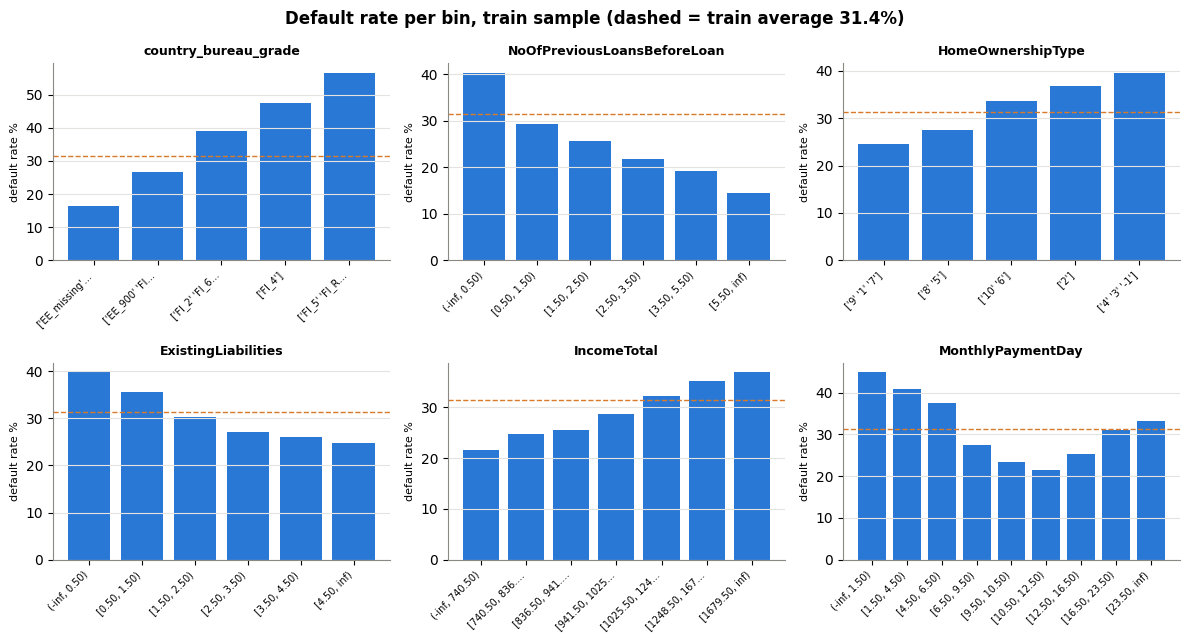

In [7]:
SHOW = ["country_bureau_grade", "NoOfPreviousLoansBeforeLoan", "HomeOwnershipType",
        "ExistingLiabilities", "IncomeTotal", "MonthlyPaymentDay"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, name in zip(axes.flat, SHOW):
    t = table(name)
    ax.bar(range(len(t)), t["Event rate"] * 100, color=BLUE)
    ax.axhline(y[is_train].mean() * 100, color=ORANGE, linewidth=1, linestyle="--")  # average
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([b if len(b) <= 14 else b[:13] + "…" for b in t["Bin"]], rotation=45,
                       ha="right", fontsize=7)
    ax.set_title(name, fontsize=9)
    ax.set_ylabel("default rate %", fontsize=8)
fig.suptitle("Default rate per bin, train sample (dashed = train average 31.4%)", fontweight="bold")
plt.tight_layout(); plt.show()

In [8]:
for name in ["NoOfPreviousLoansBeforeLoan", "IncomeTotal"]:
    print(name); display(table(name))

NoOfPreviousLoansBeforeLoan


,Bin,Count,Count (%),Event rate,WoE,IV
0,"(-inf, 0.50)",34432,0.457,0.403,-0.3896,0.074
1,"[0.50, 1.50)",14869,0.197,0.293,0.097455,0.002
2,"[1.50, 2.50)",8535,0.113,0.257,0.27897,0.008
3,"[2.50, 3.50)",5312,0.071,0.217,0.498846,0.016
4,"[3.50, 5.50)",6124,0.081,0.191,0.661294,0.031
5,"[5.50, inf)",6030,0.080,0.145,0.991882,0.062


IncomeTotal


,Bin,Count,Count (%),Event rate,WoE,IV
0,"(-inf, 740.50)",12182,0.162,0.216,0.508268,0.037
1,"[740.50, 836.50)",4794,0.064,0.248,0.327374,0.006
2,"[836.50, 941.50)",4800,0.064,0.255,0.286975,0.005
3,"[941.50, 1025.50)",5528,0.073,0.286,0.131058,0.001
4,"[1025.50, 1248.50)",10048,0.133,0.323,-0.041795,0.000
5,"[1248.50, 1679.50)",13950,0.185,0.352,-0.171311,0.006
6,"[1679.50, inf)",24000,0.319,0.369,-0.245192,0.020


### What the result shows
* **`country_bureau_grade`** forms five groups, from 17% default (top Estonian grade `EE_1000`) to 57% (Spain together with the weakest Finnish grades). The Estonian grades fall in order (1000 safest, 500 to 900 riskier) and the Finnish grades 1 to 5 rise in order. The grouping mixes countries where the risk is the same, for example the middle Estonian grades with Finnish grade 1. That is correct for a scorecard, which scores risk, not nationality.
* **`NoOfPreviousLoansBeforeLoan`** falls steadily from 40% default for new customers to 14% for borrowers with six or more earlier Bondora loans. Classic and sensible: a borrower who was given repeat loans has repaid before.
* **`ExistingLiabilities`**: more existing liabilities, *lower* default. This looks backwards but is common in consumer credit: having several credit lines usually means other lenders have already checked and trusted the borrower, while 0 liabilities often means a thin credit file. Step 6 adds a caveat about the 0 group.
* **`HomeOwnershipType`**: owners (codes 1, 7, 9) and mortgage holders are safer than tenants (3, 4) and borrowers living with parents (2).
* **Two patterns do not make sense:**
  * **`IncomeTotal` runs the wrong way:** default *rises* with income, from 22% in the lowest bin to 37% in the highest. No credit officer would accept a scorecard that gives low earners more points.
  * **`MonthlyPaymentDay`** has nine bins with no economic direction: default is highest for payment days 1 to 4 (41% to 45%) and lowest for days 10 to 12 (22%).

### Recommended action
* Accept the bins of country, previous loans, home ownership and liabilities.
* Before using `IncomeTotal` or `MonthlyPaymentDay`, find out why they behave this way. A pattern that makes no sense is usually a data effect. Step 5 tests the most likely one: country.

## Step 5. Does each pattern hold inside each country?

### Why this step
Countries differ in two ways at once: in default rate (Estonia 19%, Finland 42%, Spain 57% in train) and in the *values* of many features. Finnish incomes are about twice Estonian ones; payment-day habits differ by country. So a feature can look predictive on the pooled data only because it tells the countries apart. This is **Simpson's paradox**. Such a feature adds nothing that `country_bureau_grade` does not already say, and its bins can point the wrong way inside every country.

The test: for each feature, take its bins in order of WoE (safest first) and compute the default rate of each bin **within** each country (bins with at least 100 loans in that country). If the pattern is real, the safest bins should have the lowest default rate in every country: a Spearman rank correlation close to -1 between WoE and the within-country default rate. A value near 0 or positive means the pooled pattern is a country effect.

**Rule (D-018):** a feature passes if the median of its three within-country correlations is -0.5 or lower. The country features themselves are exempt.

In [9]:
COUNTRY_FEATURES = ["Country", "CreditScoreEeMini", "CreditScoreFiAsiakasTietoRiskGrade",
                    "country_bureau_grade"]
woe_train = bp.transform(X[is_train], metric="woe").set_index(X.index[is_train])
country = X.loc[is_train, "Country"]


def within_country(name: str) -> pd.Series:
    """Spearman correlation between bin WoE and the default rate of the bin, per country."""
    t = pd.DataFrame({"woe": woe_train[name], "country": country, "y": y[is_train]})
    out = {}
    for c, g in t.groupby("country"):
        rates = g.groupby("woe")["y"].agg(["mean", "size"]).query("size >= 100")
        out[c] = rates.index.to_series().corr(rates["mean"], method="spearman") if len(rates) >= 2 else np.nan
    return pd.Series(out)


check_names = [n for n in iv.index if iv.loc[n, "iv"] >= 0.02 and n not in COUNTRY_FEATURES]
by_country = pd.DataFrame({n: within_country(n) for n in check_names}).T.round(2)
by_country["median"] = by_country.median(axis=1)
by_country["passes"] = by_country["median"] <= -0.5
by_country.join(iv["iv"]).sort_values("median")

,EE,ES,FI,median,passes,iv
NewCreditCustomer,-1.00,-1.00,-1.00,-1.00,True,0.166
LiabilitiesTotal,-1.00,-1.00,-1.00,-1.00,True,0.037
income_vs_country_median,-0.40,-1.00,-1.00,-1.00,True,0.022
NoOfPreviousLoansBeforeLoan,-1.00,-0.94,-0.94,-0.94,True,0.193
ExistingLiabilities,-1.00,-0.83,-0.60,-0.83,True,0.073
HomeOwnershipType,-0.80,-0.60,-1.00,-0.80,True,0.092
AppliedAmount,-1.00,-0.20,-0.60,-0.60,True,0.066
Education,-0.80,-0.60,-0.60,-0.60,True,0.027
AmountOfPreviousLoansBeforeLoan,-0.54,-0.89,-0.50,-0.54,True,0.171
Amount,-1.00,1.00,-0.50,-0.50,True,0.050


In [10]:
# Default rate per bin, inside each country, for the three features the check is about.
for name in ["IncomeTotal", "income_vs_country_median", "MonthlyPaymentDay"]:
    t = pd.DataFrame({"bin": BINS["train"][name].values, "woe": woe_train[name].values,
                      "country": country.values, "y": y[is_train].values})
    print(name, "(rows from safest to riskiest pooled bin; values = default rate in that country)")
    display(t.pivot_table(index=["woe", "bin"], columns="country", values="y", aggfunc="mean")
             .sort_index(ascending=False).droplevel(0).round(3))

IncomeTotal (rows from safest to riskiest pooled bin; values = default rate in that country)


country,EE,ES,FI
bin,,,
"(-inf, 740.50)",0.195,0.610,0.346
"[740.50, 836.50)",0.203,0.630,0.439
"[836.50, 941.50)",0.192,0.604,0.405
"[941.50, 1025.50)",0.197,0.603,0.404
"[1025.50, 1248.50)",0.165,0.603,0.448
"[1248.50, 1679.50)",0.181,0.583,0.446
"[1679.50, inf)",0.179,0.522,0.416


income_vs_country_median (rows from safest to riskiest pooled bin; values = default rate in that country)


country,EE,ES,FI
bin,,,
"[1.99, inf)",0.163,0.442,0.341
"[1.49, 1.99)",0.193,0.509,0.359
"[1.19, 1.49)",0.176,0.567,0.397
"(-inf, 1.19)",0.192,0.598,0.443


MonthlyPaymentDay (rows from safest to riskiest pooled bin; values = default rate in that country)


country,EE,ES,FI
bin,,,
"[10.50, 12.50)",0.181,0.553,0.436
"[9.50, 10.50)",0.176,0.603,0.514
"[12.50, 16.50)",0.196,0.601,0.411
"[6.50, 9.50)",0.172,0.591,0.419
"[16.50, 23.50)",0.207,0.541,0.405
"[23.50, inf)",0.214,0.545,0.416
"[4.50, 6.50)",0.174,0.602,0.461
"[1.50, 4.50)",0.149,0.569,0.421
"(-inf, 1.50)",0.186,0.566,0.430


### What the result shows
* **`IncomeTotal` fails** (median +0.71). Inside Estonia and Spain, more income goes with slightly *less* default; inside Finland the pattern is mixed. The pooled "more income, more default" is the country mix: the high-income bins are full of Finnish borrowers. Classic Simpson's paradox.
* **`income_vs_country_median` passes** (median -1.0). Measured against the country's own median, more income means clearly less default in Spain (from 60% to 44%) and Finland (from 44% to 34%). In Estonia the effect is small: only the top bin (twice the median or more) is clearly safer. It is weak overall (IV 0.022), but it points the right way, and it is the version of income a credit officer can defend.
* **`MonthlyPaymentDay` fails clearly** (median +0.10): inside each country the payment day says nothing about default. Its pooled IV of 0.12 came entirely from countries using different payment days.
* **`VerificationType` fails as well** (+1.0): inside Estonia and Spain its pooled order is reversed. It is also dropped for its population shift in step 7.
* **Previous loans, home ownership, liabilities, applied amount and education pass.** `Education` passes at -0.6: inside every country higher education is the safest group, while pooled, the secondary group comes first, because Spain has many highly educated borrowers. `Amount` and `LoanDuration` pass only just (-0.5); both are dropped later for other reasons.

### Recommended action
* Drop `IncomeTotal` and `MonthlyPaymentDay`, and use `income_vs_country_median` for income.
* Run this check whenever a feature is added: on Bondora data, country explains so much that any feature that differs by country will look predictive.

## Step 6. Two questions from earlier phases

### Why this step
**6a. LanguageCode (D-016).** The registry used to list `LanguageCode` (the language the borrower uses with Bondora) as a candidate. Notebook 04's first run gave it the highest IV of all (0.53). The table below shows why, and why it was moved to the `protected` class: it repeats `Country`, except inside Estonia, where it separates Estonian speakers from Russian speakers. In Estonia, language spoken is closely tied to ethnic origin. Using it would price borrowers by ethnicity, which EU non-discrimination law forbids and the EU AI Act treats as a key risk for credit scoring. It stays in the data for the fairness analysis in Phase 4, as `Age` and `Gender` do.

**6b. Liabilities before and after June 2017 (D-015, "watch").** `ExistingLiabilities` and `LiabilitiesTotal` are never 0 before the June 2017 form change but 0 for about a quarter of loans afterwards. If the meaning changed, the bins learned on the mix of both periods could be wrong for recent loans.

In [11]:
# 6a. Language by country, and the default rate of each language inside Estonia (train loans).
lang = sql("""
SELECT s.loan_key, l."LanguageCode" AS language_code, l."Country" AS country
FROM loans l JOIN sample_keys s USING (loan_key)
""").set_index("loan_key").loc[X.index[is_train]]
lang["y"] = y[is_train]
display(pd.crosstab(lang["language_code"], lang["country"]))
(lang[lang["country"] == "EE"].groupby("language_code")["y"].agg(loans="size", default_rate="mean")
    .query("loans >= 100").round(3))

country,EE,ES,FI
language_code,,,
1,35549,3,47
2,301,79,188
3,7396,1,14
4,21,0,18493
5,0,3,0
6,1,13204,0
22,0,0,2


,loans,default_rate
language_code,,
1,35549,0.177
2,301,0.213
3,7396,0.234


In [12]:
# 6b. Default rate per ExistingLiabilities bin, before and after the June 2017 form change.
period = np.where(samples.loc[is_train, "issue_date"] < pd.Timestamp("2017-06-01"),
                  "before Jun 2017", "from Jun 2017")
liab = pd.DataFrame({"bin": BINS["train"]["ExistingLiabilities"].values, "period": period,
                     "y": y[is_train].values})
liab.pivot_table(index="bin", columns="period", values="y", aggfunc=["size", "mean"]).round(3)

size                          mean              
period       before Jun 2017 from Jun 2017 before Jun 2017 from Jun 2017
bin                                                                     
(-inf, 0.50)             NaN       15887.0             NaN         0.398
[0.50, 1.50)          1299.0       14100.0           0.507         0.343
[1.50, 2.50)          1748.0        9593.0           0.332         0.297
[2.50, 3.50)          1593.0        6724.0           0.303         0.264
[3.50, 4.50)          1377.0        4849.0           0.288         0.252
[4.50, inf)           4969.0       13163.0           0.329         0.217

### What the result shows
* **6a.** Code 1 (Estonian) and code 3 (Russian) are almost only used in Estonia, code 4 (Finnish) in Finland and code 6 (Spanish) in Spain. Inside Estonia, Russian-speaking borrowers default more often (23.4% against 17.7%). That gap is exactly what the model must not use directly. `country_bureau_grade` already captures the country part.
* **6b.** From June 2017, the 0 bin of `ExistingLiabilities` holds about a quarter of loans, with the highest default rate (about 40%). Before June 2017 the 0 bin does not exist, and the 1-liability bin is the riskiest (about 51%). So "0 liabilities" after the change probably covers what "1 liability" meant before (perhaps the Bondora loan itself was counted earlier). The direction (fewer liabilities, more risk) is the same in both periods, and the out-of-time sample is entirely "from June 2017", where the 0 bin exists.

### Recommended action
* Keep `LanguageCode` out of the model (D-016). Use it in the Phase 4 fairness check: compare scores and approval rates by language inside Estonia.
* Keep `ExistingLiabilities`. Mention the definition change in the data card. In notebook 05, check the score's ranking separately for loans issued before and after June 2017.

## Step 7. Stability: do the features look the same in 2020 to 2021?

### Why this step
A scorecard is used on future applicants. If the mix of a feature changes a lot (for example, Bondora starts verifying every applicant's income), the bins and their WoE may no longer mean the same thing. PSI measures the change in each feature's bin shares:

* train vs **test**: should be about 0, because test was drawn at random from the same years;
* train vs **out-of-time**: the real question.

PSI uses only the feature values, not the target, so computing it on the out-of-time sample does not break the "blind" rule. Thresholds (roadmap): below 0.10 stable, 0.10 to 0.25 monitor, above 0.25 a real shift.

In [13]:
def psi(expected: pd.Series, actual: pd.Series) -> float:
    """Population stability index between two sets of bin labels."""
    e = expected.value_counts(normalize=True)
    a = actual.value_counts(normalize=True)
    idx = e.index.union(a.index)
    e, a = e.reindex(idx, fill_value=0) + 1e-6, a.reindex(idx, fill_value=0) + 1e-6
    return float(((a - e) * np.log(a / e)).sum())


iv["psi_test"] = [round(psi(BINS["train"][c], BINS["test"][c]), 3) for c in iv.index]
iv["psi_oot"] = [round(psi(BINS["train"][c], BINS["oot"][c]), 3) for c in iv.index]
iv["stability"] = pd.cut(iv["psi_oot"], [-1, 0.10, 0.25, 99], labels=["stable", "monitor", "shift"])
iv[["iv", "psi_test", "psi_oot", "stability"]].sort_values("psi_oot", ascending=False)

,iv,psi_test,psi_oot,stability
name,,,,
VerificationType,0.059,0.000,0.705,shift
LoanDuration,0.025,0.000,0.276,shift
Country,0.523,0.000,0.159,monitor
EmploymentDurationCurrentEmployer,0.018,0.000,0.146,monitor
country_bureau_grade,0.572,0.000,0.128,monitor
CreditScoreEeMini,0.512,0.000,0.114,monitor
MonthlyPaymentDay,0.115,0.000,0.111,monitor
ExistingLiabilities,0.073,0.000,0.101,monitor
Education,0.027,0.000,0.080,stable


In [14]:
# The two features that shifted: their bin shares in train and out-of-time.
for name in ["VerificationType", "LoanDuration"]:
    shares = pd.DataFrame({w: BINS[w][name].value_counts(normalize=True) for w in ["train", "oot"]})
    print(name); display((shares * 100).round(1).fillna(0))

VerificationType


,train,oot
VerificationType,,
['4'],56.0,90.7
['1' '3'],44.0,9.3


LoanDuration


,train,oot
LoanDuration,,
"[42.00, inf)",55.5,72.8
"[33.00, 42.00)",37.3,15.0
"(-inf, 33.00)",7.2,12.2


### What the result shows
* Train vs test PSI is 0 for every feature, as it should be.
* **Two features shift beyond 0.25 out of time:**
  * `VerificationType` (PSI 0.71): in 2016 to 2019 about 56% of loans had the highest verification level; in 2020 to 2021 about 91% did, and one level disappeared. Bondora changed its process, so the feature now separates almost nobody.
  * `LoanDuration` (PSI 0.28): the mix of loan terms changed (more long-term loans).
* **Monitor (0.10 to 0.25):** the country features (Spain almost disappears in 2020), `MonthlyPaymentDay`, `ExistingLiabilities` and `EmploymentDurationCurrentEmployer`. These are expected population changes rather than broken features.

### Recommended action
* Drop `VerificationType` and `LoanDuration` from the shortlist: both are weak (IV 0.06 and 0.02) and their populations have moved. A weak feature with a large shift adds more risk than information.
* Report the PSI of every shortlisted feature in the model documentation and monitor it in Phase 6.

## Step 8. Remove duplicates: correlation and VIF

### Why this step
Several features describe the same thing: the amount applied for and the amount granted; the number and the total amount of previous loans; `Country` and `country_bureau_grade`. In a logistic regression, two near-copies share one effect between them in an unstable way: their weights can swing, even flip sign, from one sample to the next, and the scorecard becomes hard to explain.

The code below applies all the selection rules of this notebook (D-018) and writes down a reason for every feature it drops:

1. IV on train at least 0.02 (step 3).
2. Population stable out of time: PSI at most 0.25 (step 7).
3. Pattern holds inside each country (step 5).
4. A derived feature replaces its raw inputs: `country_bureau_grade` replaces `Country` and the two bureau scores; `income_vs_country_median` replaces `IncomeTotal`.
5. From the highest IV down, drop a feature whose WoE correlation with a feature already kept is above 0.7 (roadmap Phase 3).
6. Every shortlisted feature must have VIF below 5.

In [15]:
woe = bp.transform(X[is_train], metric="woe")      # WoE value of every feature, train loans
corr = woe.corr()
pairs = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns)
         for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) > 0.7]
pd.DataFrame(pairs, columns=["feature_a", "feature_b", "woe_correlation"]).sort_values(
    "woe_correlation", ascending=False)

,feature_a,feature_b,woe_correlation
4,AppliedAmount,Amount,0.96
3,Country,country_bureau_grade,0.95
7,CreditScoreEeMini,country_bureau_grade,0.93
6,NoOfPreviousLoansBeforeLoan,AmountOfPreviousLoansBeforeLoan,0.92
2,Country,CreditScoreEeMini,0.85
0,NewCreditCustomer,NoOfPreviousLoansBeforeLoan,0.84
1,NewCreditCustomer,AmountOfPreviousLoansBeforeLoan,0.82
5,ExistingLiabilities,LiabilitiesTotal,0.74


In [16]:
# Apply the selection rules and record a reason for every feature.
reason = {}
for name in iv.index:
    if iv.loc[name, "iv"] < 0.02:
        reason[name] = f"IV {iv.loc[name, 'iv']:.3f} below 0.02"
    elif iv.loc[name, "psi_oot"] > 0.25:
        reason[name] = f"population shift, PSI {iv.loc[name, 'psi_oot']:.2f}"
    elif name in by_country.index and not by_country.loc[name, "passes"]:
        reason[name] = f"country effect (within-country correlation {by_country.loc[name, 'median']:+.2f})"
for name, inputs in reg.derived.items():                 # rule 4: derived replaces its inputs
    for raw in inputs:
        reason.setdefault(raw, f"input of {name}")

kept = []
for name in iv.index:                                    # rule 5: highest IV first
    if name in reason:
        continue
    clash = [k for k in kept if abs(corr.loc[name, k]) > 0.7]
    if clash:
        reason[name] = f"duplicates {clash[0]} (correlation {corr.loc[name, clash[0]]:.2f})"
    else:
        kept.append(name)

# Rule 6: VIF of each kept feature (a constant column is added, as statsmodels expects).
W = np.column_stack([np.ones(is_train.sum()), woe[kept].to_numpy()])
vif = {name: variance_inflation_factor(W, i + 1) for i, name in enumerate(kept)}

shortlist = iv.loc[kept, ["n_bins", "iv", "iv_test", "psi_oot"]].assign(vif=[round(vif[k], 2) for k in kept])
dropped = pd.DataFrame({"iv": iv.loc[list(reason), "iv"], "reason": pd.Series(reason)}).sort_values(
    "iv", ascending=False)
print(f"Shortlist: {len(kept)} features   Dropped: {len(dropped)}")
display(shortlist)
dropped

Shortlist: 7 features   Dropped: 15


,n_bins,iv,iv_test,psi_oot,vif
name,,,,,
country_bureau_grade,5,0.572,0.567,0.128,1.24
NoOfPreviousLoansBeforeLoan,6,0.193,0.180,0.015,1.87
HomeOwnershipType,5,0.092,0.097,0.040,1.05
ExistingLiabilities,6,0.073,0.067,0.101,1.64
AppliedAmount,4,0.066,0.062,0.035,1.17
Education,4,0.027,0.022,0.080,1.03
income_vs_country_median,4,0.022,0.024,0.027,1.03


,iv,reason
Country,0.523,input of country_bureau_grade
CreditScoreEeMini,0.512,input of country_bureau_grade
AmountOfPreviousLoansBeforeLoan,0.171,duplicates NoOfPreviousLoansBeforeLoan (correl...
NewCreditCustomer,0.166,duplicates NoOfPreviousLoansBeforeLoan (correl...
MonthlyPaymentDay,0.115,country effect (within-country correlation +0.10)
CreditScoreFiAsiakasTietoRiskGrade,0.092,input of country_bureau_grade
IncomeTotal,0.076,country effect (within-country correlation +0.71)
VerificationType,0.059,"population shift, PSI 0.70"
Amount,0.050,duplicates AppliedAmount (correlation 0.96)
LiabilitiesTotal,0.037,duplicates ExistingLiabilities (correlation 0.74)


### What the result shows
* Eight pairs correlate above 0.7, as expected: the three country features with each other, `Amount` with `AppliedAmount` (0.96), the previous-loan count with the previous-loan amount (0.92) and with `NewCreditCustomer` (0.84), and the two liability measures (0.74).
* **Seven features are shortlisted:** `country_bureau_grade`, `NoOfPreviousLoansBeforeLoan`, `HomeOwnershipType`, `ExistingLiabilities`, `AppliedAmount`, `Education` and `income_vs_country_median`.
* **Every VIF is below 2**, far under the limit of 5: once duplicates are removed, each feature brings its own information.
* Every dropped feature has a written reason: too weak, shifted, a country effect, an input of a derived feature, or a duplicate of a stronger feature.
* Seven features is below the 8 to 15 Siddiqi suggests for a scorecard. That is a property of this data, not of the method: after the June 2017 form change Bondora stopped storing 18 fields (D-009, D-015), and a scorecard can only use what is collected today. The LightGBM challenger in Phase 3 will show how much a flexible model can add on the same inputs.

### Recommended action
* Fit the scorecard in notebook 05 on these seven features.
* `Education` and `income_vs_country_median` are the weakest (IV about 0.02). Keep them only if their coefficients have the expected sign and are significant in notebook 05.

## Step 9. Save the bins and the shortlist

### Why this step
Notebook 05 must use exactly these bins and these features. Saving them avoids refitting the bins (which would give the same result, but only if every setting is copied correctly). The shortlist is also written into decision D-018, so the choice is versioned in git even though `data/` is not.

In [17]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
bp.save(str(OUT_DIR / "binning_process.pkl"))
(OUT_DIR / "scorecard_shortlist.json").write_text(json.dumps({
    "features": kept,
    "binning": {"min_bin_size": 0.05, "categorical": [c for c in kept if c in CATEGORICAL],
                "non_monotonic": [c for c in kept if c in NON_MONOTONIC]},
    "fitted_on": "train sample, data/processed/model_samples.parquet",
}, indent=2), encoding="utf-8")

check = BinningProcess.load(str(OUT_DIR / "binning_process.pkl"))      # read back and compare
same = check.transform(X[is_test].head(1000), metric="woe").equals(
    bp.transform(X[is_test].head(1000), metric="woe"))
print("Saved binning_process.pkl and scorecard_shortlist.json; reloaded bins identical:", same)

Saved binning_process.pkl and scorecard_shortlist.json; reloaded bins identical: True


### What the result shows
Both files are written, and the reloaded bins give identical WoE values.

### Recommended action
Notebook 05 loads `binning_process.pkl` and the shortlist. Later, move the binning settings into `src/pdengine/` so `make train` can rebuild everything without the notebooks.

## Step 10. Summary of findings and recommended actions

### Findings

| # | Area | Finding | Action | Decision |
|---|---|---|---|---|
| 1 | Zero-coded fields | Ten income and affordability fields are 0 for every loan from June 2017 (found before binning). | Removed from the candidates. | D-015 |
| 2 | Language | `LanguageCode` repeats `Country` and, inside Estonia, separates Russian from Estonian speakers (23.4% vs 17.7% default): a proxy for ethnicity. | Moved to `protected`; used only for fairness checks. | D-016 |
| 3 | Bureau scores | Each score exists only for its own country; pooled, it mostly repeats `Country`. | Combined into `country_bureau_grade` (IV 0.57, strongest feature). | D-017 |
| 4 | IV | Country features strong (above 0.5, not leaks); previous loans medium; four features below 0.02. Test IV matches train IV. | Drop the four; bins generalise. | |
| 5 | Business sense | Country, previous loans, home ownership and liabilities follow sensible patterns. Raw income runs the wrong way; payment day has no direction. | Investigated in step 5. | |
| 6 | Country effects | `IncomeTotal` and `MonthlyPaymentDay` look predictive only because they differ by country (Simpson's paradox). Income relative to the country median works the right way. | Both dropped; `income_vs_country_median` added. | D-017, D-018 |
| 7 | Liabilities | "0 liabilities" exists only from June 2017 and is the riskiest bin; the direction is the same in both periods. | Keep; check ranking before and after June 2017 in 05; note in data card. | D-015 |
| 8 | Stability | `VerificationType` (PSI 0.71) and `LoanDuration` (0.28) shifted out of time. | Dropped. | D-018 |
| 9 | Duplicates | Eight pairs above 0.7 correlation. | Kept the higher-IV feature of each; VIF below 2 for all. | D-018 |
| 10 | Shortlist | 7 features: `country_bureau_grade`, `NoOfPreviousLoansBeforeLoan`, `HomeOwnershipType`, `ExistingLiabilities`, `AppliedAmount`, `Education`, `income_vs_country_median`. | Fit the scorecard in notebook 05. | D-018 |

### What this means for the next phase

Notebook 05 fits a logistic regression on the WoE values of the seven features (train), checks that every coefficient has the expected sign and is significant, turns the model into score points, and then, for the first time, measures Gini, KS and calibration on the test and out-of-time samples.

### Binning in one paragraph (for my video)

A credit scorecard does not use raw numbers. Each feature is cut into a few groups, and each group gets a weight of evidence: how much safer or riskier it is than average. I learned the groups on the training loans only and checked they hold on the test loans. Three findings shaped the model. First, Bondora stopped storing income details and affordability ratios in 2017, so ten fields are always zero for recent loans and had to go. Second, the language field turned out to be a proxy for ethnicity in Estonia, so I took it out of the model and kept it only to test fairness. Third, each country has its own credit bureau score, so I combined country and bureau grade into one feature, which became the strongest in the model. Country also fooled two features: income looked like it raised risk and the payment day looked predictive, but inside each country neither pattern held. That is Simpson's paradox, so I measured income against each country's median instead and dropped the payment day. After removing weak, unstable and duplicate features, seven remain, and I never looked at how they perform on the out-of-time loans: that test stays clean for the final model.

In [18]:
con.close()   # release the warehouse file